# Chương 9 — Acoustic Modeling (Mô hình hóa âm học)
## Giải thích cho người mới + thực hành `NLinh_1.wav`

**Nguồn chính:** Huang, Acero & Hon, *Spoken Language Processing*, Chương 9, “Acoustic Modeling”, trang in 413–465 (số trang PDF có thể khác trang in).

Notebook có hai phần: (1) lý thuyết, ví dụ tính tay; (2) phân tích tín hiệu WAV, năng lượng, phổ, Mel-spectrogram, MFCC và đặc trưng động.

> Phân biệt: sách trình bày nhận dạng tiếng nói theo hướng thống kê/HMM. MFCC là đặc trưng âm học, không phải mô hình nhận dạng hay nhãn `human/AI`. Ví dụ số trong phần lý thuyết dưới đây là số minh họa do notebook tạo, không phải số liệu thực nghiệm của sách.

## 1. Bài toán nhận dạng tiếng nói và công thức Bayes

Hệ thống nhận âm thanh, biến nó thành chuỗi đặc trưng $X=(x_1,\ldots,x_T)$, rồi chọn chuỗi từ $W$ phù hợp nhất.

$$
\hat W=\arg\max_W P(W\mid X)
\tag{9.1}
$$

Theo định lý Bayes:

$$
P(W\mid X)=\frac{P(X\mid W)P(W)}{P(X)}
$$

Vì $X$ đã cố định, $P(X)$ là như nhau khi so sánh các giả thuyết từ $W$. Do đó:

$$
\boxed{\hat W=\arg\max_W P(X\mid W)P(W)}
\tag{9.2}
$$

- $X$: chuỗi vector đặc trưng từ âm thanh.
- $W$: một giả thuyết chuỗi từ.
- $P(X\mid W)$: xác suất âm học — chuỗi đặc trưng có phù hợp với cách phát âm giả thuyết không?
- $P(W)$: xác suất ngôn ngữ — chuỗi từ có hợp lý theo ngôn ngữ không?
- $P(W\mid X)$: xác suất hậu nghiệm sau khi quan sát âm thanh.
- $\arg\max_W$: chọn giả thuyết $W$ làm cho điểm số đạt cực đại.

### Ví dụ tính tay (số giả định)

Hai giả thuyết:
- $W_1$: “một con mèo”; $P(X\mid W_1)=0.08$, $P(W_1)=0.10$
- $W_2$: “một con kéo”; $P(X\mid W_2)=0.04$, $P(W_2)=0.30$

Điểm chưa chuẩn hóa:
$$
S_1=0.08(0.10)=0.008,\quad S_2=0.04(0.30)=0.012
$$
Chuẩn hóa hai giả thuyết:
$$
P(W_1\mid X)=\frac{0.008}{0.020}=0.4,\quad
P(W_2\mid X)=\frac{0.012}{0.020}=0.6
$$
Dù bằng chứng âm học nghiêng về $W_1$, mô hình ngôn ngữ khiến $W_2$ có điểm kết hợp cao hơn. Ví dụ này cho thấy mô hình ngôn ngữ có thể giúp, nhưng cũng có thể lấn át bằng chứng âm thanh nếu được cân quá mạnh.

## 2. Mục 9.1 — Các nguồn biến thiên của tiếng nói

Sách chia thành bốn nhóm:

1. **Context variability — ngữ cảnh:** một âm vị thay đổi theo âm đứng trước/sau do đồng cấu âm (*coarticulation*). Cùng một âm /t/ trong những từ khác nhau không có phổ hoàn toàn giống nhau.
2. **Style variability — phong cách:** đọc rõ, nói tự nhiên, nói nhanh, thì thầm, hét, ngập ngừng.
3. **Speaker variability — người nói:** giọng vùng miền, thói quen phát âm, cao độ, cấu tạo đường thanh, tốc độ.
4. **Environment variability — môi trường:** tiếng ồn, micro, khoảng cách, vang phòng, nén âm thanh.

### Ví dụ tính tay

Giả sử RMS của cùng một âm khi nói gần micro là 0.10, khi nói xa là 0.03. Tỉ số biên độ:
$$
r=\frac{0.10}{0.03}=3.33
$$
Chênh lệch mức biên độ:
$$
20\log_{10}(3.33)\approx10.46\text{ dB}
$$
Cùng người nói nhưng điều kiện thu làm mức âm thay đổi hơn 10 dB. Mô hình cần đủ dữ liệu đa dạng, chuẩn hóa đặc trưng hoặc thích nghi để giảm sai khác này.

## 3. Mục 9.2 — Đo lỗi nhận dạng: Word Error Rate

$$
\mathrm{WER}=\frac{S+D+I}{N}
$$

- $S$: số từ bị thay thế (*substitution*).
- $D$: số từ bị xóa (*deletion*).
- $I$: số từ chèn thêm (*insertion*).
- $N$: tổng số từ trong bản chép tham chiếu (*reference*).

Ví dụ: tham chiếu `tôi muốn uống trà` có 4 từ; dự đoán `tôi muốn uống cà phê`. Căn chỉnh minh họa: `trà` bị thay bằng `cà` ($S=1$), `phê` là từ chèn ($I=1$), $D=0$.
$$
\mathrm{WER}=\frac{1+0+1}{4}=0.5=50\%
$$
WER có thể lớn hơn 100% nếu chèn nhiều từ. Cần thống nhất cách chuẩn hóa chữ hoa/thường, dấu câu và số trước khi tính. Không có bản chép đúng (ground truth) thì không thể tính WER đáng tin cậy.

## 4. Mục 9.3 — Trích xuất đặc trưng

### 4.1 Lấy mẫu

Nếu $f_s=16\,000\text{ Hz}$ và đoạn dài $T=2\text{ giây}$:
$$
N=f_sT=16\,000\times2=32\,000\text{ mẫu}
$$
Tần số Nyquist là $f_s/2$, tức 8 kHz trong ví dụ này.

### 4.2 Chia khung

Ví dụ $f_s=16\text{ kHz}$, độ dài khung 25 ms, bước nhảy 10 ms:
$$
N_f=0.025(16\,000)=400\text{ mẫu}
$$
$$
N_h=0.010(16\,000)=160\text{ mẫu}
$$
Chồng lấn $400-160=240$ mẫu = 15 ms = 60%.

Cửa sổ Hann:
$$
w[n]=\frac12\left(1-\cos\frac{2\pi n}{N-1}\right)
$$
Khung được nhân với cửa sổ $x_w[n]=x[n]w[n]$ nhằm giảm rò rỉ phổ do cắt tín hiệu.

### 4.3 STFT

$$
X(m,k)=\sum_{n=0}^{N-1}x[n+mH]w[n]e^{-j2\pi kn/N}
$$
$m$ là chỉ số khung; $k$ là bin tần số; $H$ là bước nhảy (hop length). $|X(m,k)|$ là độ lớn phổ, còn $|X(m,k)|^2$ là công suất phổ.

### 4.4 Mel và MFCC

Công thức Mel thường dùng:
$$
m(f)=2595\log_{10}\left(1+\frac{f}{700}\right)
$$
Với $f=1000\text{ Hz}$:
$$
m(1000)=2595\log_{10}(1+1000/700)\approx1000\text{ Mel}
$$

Sau bộ lọc Mel, gọi năng lượng dải thứ $m$ là $E_m$. Lấy log:
$$
L_m=\ln(E_m+\epsilon)
$$
$\epsilon$ nhỏ để tránh log của 0. Sau đó áp dụng DCT-II:
$$
c_n=\sum_{m=0}^{M-1}L_m
\cos\left[\frac{\pi n}{M}\left(m+\frac12\right)\right]
$$
Đây là công thức chưa ghi hệ số chuẩn hóa. Thư viện có thể dùng DCT trực giao nên kết quả khác hệ số tỉ lệ.

**Ví dụ số:** giả sử log năng lượng 3 dải $L=[0,\ln2,\ln4]\approx[0,0.6931,1.3863]$, số dải lọc $M=3$:
$$
c_0=0+0.6931+1.3863=2.0794
$$
$$
c_1\approx0(0.866)+0.6931(0)+1.3863(-0.866)\approx-1.2006
$$
MFCC không phải tần số Hz; nó là hệ số mô tả hình dạng phổ log-Mel. Thực tế thường giữ 13–20 hệ số đầu.

### 4.5 Delta và delta-delta

$$
\Delta c_t=\frac{\sum_{n=1}^{K}n(c_{t+n}-c_{t-n})}
{2\sum_{n=1}^{K}n^2}
$$
Với $K=2$, mẫu số là $2(1^2+2^2)=10$. Delta mô tả xu hướng thay đổi theo thời gian; delta-delta là delta tính trên chuỗi delta. Ghép 13 MFCC + 13 delta + 13 delta-delta tạo vector 39 chiều mỗi khung.

## 5. Mục 9.4 — Chọn đơn vị ngữ âm

Các lựa chọn được thảo luận gồm phone/phoneme, đơn vị phụ thuộc ngữ cảnh như triphone, các trạng thái được gom cụm/chia sẻ tham số và dạng phát âm cơ sở trong từ điển.

- **Mô hình nguyên từ:** có thể mô tả tốt từ đã gặp nhưng cần nhiều ví dụ cho mọi từ và khó xử lý từ mới.
- **Phone độc lập ngữ cảnh:** tái sử dụng được, dễ tổng quát hóa hơn nhưng bỏ qua ảnh hưởng âm trước/sau.
- **Triphone:** mô tả ngữ cảnh tốt hơn nhưng số tổ hợp tăng, làm dữ liệu thưa.
- **Clustered/shared states:** nhóm trạng thái tương tự để chia sẻ dữ liệu.

Ví dụ tổ hợp thô với 40 phone:
$$
40^3=64\,000
$$
Đây là số tổ hợp lý thuyết đơn giản cho phone trái–giữa–phải, không có nghĩa tất cả đều xuất hiện trong dữ liệu. Bài toán là cân bằng độ chính xác, khả năng huấn luyện và khả năng tổng quát hóa.

## 6. Mục 9.5 — HMM chấm điểm đặc trưng

HMM (Hidden Markov Model) có:
- $s_t$: trạng thái ẩn tại khung $t$.
- $a_{ij}=P(s_t=j\mid s_{t-1}=i)$: xác suất chuyển trạng thái.
- $b_j(x_t)=P(x_t\mid s_t=j)$: xác suất phát xạ/đầu ra.
- $\pi_i=P(s_1=i)$: xác suất trạng thái ban đầu.

Xác suất của một đường trạng thái:
$$
P(X,S)=\pi_{s_1}b_{s_1}(x_1)
\prod_{t=2}^{T}a_{s_{t-1}s_t}b_{s_t}(x_t)
$$
Forward cộng điểm của mọi đường trạng thái hợp lệ; Viterbi tìm đường có điểm lớn nhất.

### Ví dụ Forward với 2 trạng thái, 2 khung

Giả sử:
- $\pi_A=0.6, \pi_B=0.4$
- $b_A(x_1)=0.5, b_B(x_1)=0.1$
- $a_{AA}=0.7, a_{AB}=0.3, a_{BA}=0.2, a_{BB}=0.8$
- $b_A(x_2)=0.4, b_B(x_2)=0.6$

Khung 1:
$$
\alpha_1(A)=0.6(0.5)=0.30,\quad\alpha_1(B)=0.4(0.1)=0.04
$$
Khung 2:
$$
\alpha_2(A)=[0.30(0.7)+0.04(0.2)]0.4=0.0896
$$
$$
\alpha_2(B)=[0.30(0.3)+0.04(0.8)]0.6=0.0732
$$
$$
P(X)=0.0896+0.0732=0.1628
$$

### Phân phối đầu ra

- **Discrete HMM:** lượng tử hóa vector thành mã rời rạc; gọn nhưng mất một phần thông tin.
- **Continuous HMM:** mô hình hóa vector liên tục bằng Gaussian/GMM.
- **Semi-continuous HMM:** chia sẻ bộ phân phối/codebook giữa trạng thái, là một thỏa hiệp.

Gaussian đa biến:
$$
\mathcal N(x;\mu,\Sigma)=
\frac{\exp[-\frac12(x-\mu)^T\Sigma^{-1}(x-\mu)]}
{(2\pi)^{d/2}|\Sigma|^{1/2}}
$$
$d$ là số chiều; $\mu$ là vector trung bình; $\Sigma$ là ma trận hiệp phương sai. GMM:
$$
b_j(x)=\sum_{k=1}^{K}w_{jk}\mathcal N(x;\mu_{jk},\Sigma_{jk})
$$
với $w_{jk}\ge0$ và tổng trọng số bằng 1 ($\sum_{k=1}^K w_{jk}=1$). Nhiều Gaussian giúp một trạng thái mô tả nhiều kiểu âm học. Trong tính toán dài, thường dùng log-probability để tránh underflow: $\log\prod_t p_t=\sum_t\log p_t$.

## 7. Mục 9.6 — Thích nghi mô hình: MAP và MLLR

### MAP — Maximum a Posteriori

$$
\hat\theta_{\mathrm{MAP}}=\arg\max_\theta P(D\mid\theta)P(\theta)
$$
$D$ là dữ liệu thích nghi; $\theta$ là tham số; $P(\theta)$ là prior giúp giữ tham số gần mô hình ban đầu khi dữ liệu mới ít.

Ví dụ dạng co rút một chiều: mean gốc $\mu_0=10$ có sức nặng tương đương $r=5$ mẫu; dữ liệu mới có $N=3$ mẫu với mean $\bar x=14$:
$$
\mu_{\mathrm{new}}=\frac{r\mu_0+N\bar x}{r+N}
=\frac{5(10)+3(14)}{8}=11.5
$$
Kết quả nằm giữa 10 và 14. Đây là ví dụ minh họa cập nhật trung bình có prior, không phải toàn bộ công thức MAP của GMM-HMM.

### MLLR — Maximum Likelihood Linear Regression

$$
\hat\mu=A\mu+b
$$
$\mu$ là mean gốc, $A$ là ma trận biến đổi, $b$ là vector bias, $\hat\mu$ là mean sau thích nghi. Ví dụ một chiều: với $\mu=10, A=1.2, b=2$ thì $\hat\mu=1.2(10)+2=14$.

MAP cập nhật tham số theo dữ liệu và prior; MLLR học một phép biến đổi có thể chia sẻ giữa nhóm trạng thái. Hiệu quả tùy lượng dữ liệu và độ lệch, không có phương pháp luôn tốt nhất.

## 8. Mục 9.7 — Confidence measures

Confidence là tín hiệu ước lượng mức đáng tin của kết quả, không mặc nhiên là xác suất đúng đã được hiệu chỉnh. Sách đề cập:
- **Filler models:** mô hình cho âm thanh không khớp tốt với các đơn vị dự kiến.
- **Transformation models:** dùng phép biến đổi/đặc trưng để phân biệt kết quả đúng và sai.
- **Combination models:** kết hợp nhiều tín hiệu như điểm âm học, điểm ngôn ngữ, độ ổn định từ.

Ví dụ điểm chuẩn hóa cho ba giả thuyết: 0.72, 0.18, 0.10. Khoảng cách giữa hai giả thuyết đầu là $0.72-0.18=0.54$. Khoảng cách lớn có thể là tín hiệu hữu ích, nhưng không chứng minh xác suất đúng là 72%. Muốn dùng điểm như xác suất cần hiệu chỉnh và đánh giá trên dữ liệu có nhãn.

## 9. Mục 9.8 — Neural networks và segment models

### Neural networks

Mạng feed-forward cơ bản không tự nhiên xử lý căn chỉnh hai chuỗi không đồng bộ. Sách giới thiệu RNN, TDNN và cách kết hợp neural network với HMM.

Một RNN cơ bản:
$$
h_t=\phi(W_xx_t+W_hh_{t-1}+b_h),\quad
o_t=g(W_oh_t+b_o)
$$
$h_t$ là trạng thái ẩn chứa thông tin hiện tại và quá khứ. TDNN nhìn nhiều khung lân cận để phân loại đơn vị ngữ âm. Mạng có thể cung cấp điểm trạng thái, còn HMM xử lý chuyển trạng thái và chuỗi thời gian.

### Segment models

$$
P(X_{1:L},L\mid s)=P(X_{1:L}\mid s,L)P(L\mid s)
$$
$L$ là độ dài đoạn, $s$ là trạng thái. Segment model chấm điểm cả đoạn và thời lượng thay vì giả định mỗi khung độc lập có điều kiện. Có thể mô hình hóa cấu trúc thời gian phong phú hơn nhưng tính toán/giải mã đắt hơn.

## 10. Mục 9.9–9.10 — Case study và kết luận lịch sử

Mục 9.9 trong sách mô tả hệ thống **Microsoft Whisper** ở bối cảnh cuốn sách xuất bản năm 2000. Không được nhầm hệ thống này với mô hình Whisper hiện đại của OpenAI, ra đời nhiều năm sau.

Thông điệp của chương:
1. Lỗi nhận dạng đến từ ngữ cảnh, phong cách, người nói và môi trường.
2. Cần trích xuất đặc trưng âm học thích hợp.
3. Đơn vị ngữ âm phải vừa mô tả chính xác vừa đủ dữ liệu để huấn luyện.
4. HMM kết hợp phát xạ, chuyển trạng thái và căn chỉnh thời gian.
5. Thích nghi giúp giảm chênh lệch giữa người/môi trường mới với dữ liệu huấn luyện.
6. Neural network và segment model là các hướng mở rộng với đánh đổi riêng.

| Thành phần | Câu hỏi chính |
|---|---|
| Feature extraction | Âm thanh biểu diễn thành vector nào? |
| Phonetic modeling | Dùng phone/triphone/đơn vị nào? |
| Acoustic scoring | Đặc trưng có phù hợp với trạng thái/chuỗi từ không? |
| Adaptation | Làm sao giảm lệch người nói/môi trường? |
| Confidence | Kết quả đáng tin đến đâu? |
| Decoder + language model | Chuỗi từ nào có điểm tổng thể tốt nhất? |

# PHẦN B — Thực hành với `NLinh_1.wav`

## 11. Cài đặt và nạp file

Nếu thiếu thư viện, chạy trong terminal của đúng môi trường Python:

```bash
python -m pip install numpy scipy matplotlib pandas soundfile librosa
```

Notebook tìm `NLinh_1.wav` ở thư mục notebook hoặc `./data/`. Nếu chạy trong môi trường hiện tại, nó cũng thử `/mnt/data/NLinh_1.wav`. Trên Windows, nên đặt file cạnh notebook hoặc sửa `AUDIO_PATH`.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from IPython.display import Audio, display

candidates = [
    Path("NLinh_1.wav"),
    Path("./data/NLinh_1.wav"),
    Path("/mnt/data/NLinh_1.wav"),
]
AUDIO_PATH = next((p for p in candidates if p.exists()), None)
if AUDIO_PATH is None:
    raise FileNotFoundError(
        "Không tìm thấy NLinh_1.wav. Đặt file cạnh notebook hoặc sửa AUDIO_PATH."
    )

audio, sr = sf.read(AUDIO_PATH)
print("File:", AUDIO_PATH.resolve())
print("Sampling rate:", sr, "Hz")
print("Shape:", audio.shape)
print("Duration:", round(len(audio) / sr, 3), "s")
print("Min/max:", float(np.min(audio)), float(np.max(audio)))
print("Channels:", 1 if audio.ndim == 1 else audio.shape[1])

File: D:\audio & speech\TH\TH_TrenLop\NLinh_1.wav
Sampling rate: 48000 Hz
Shape: (286080, 2)
Duration: 5.96 s
Min/max: -0.51275634765625 0.71002197265625
Channels: 2


`sr` là số mẫu/giây; `shape` cho biết số mẫu và số kênh. Thời lượng $T=N/f_s$. Nếu file stereo, ta lấy trung bình kênh cho phần phân tích cơ bản; điều này thuận tiện nhưng có thể làm mất thông tin không gian hoặc triệt tiêu một số thành phần nếu hai kênh lệch pha.

Duration: 5.960 s
RMS amplitude: 0.046946
Peak amplitude: 0.327133
Crest factor: 16.86 dB


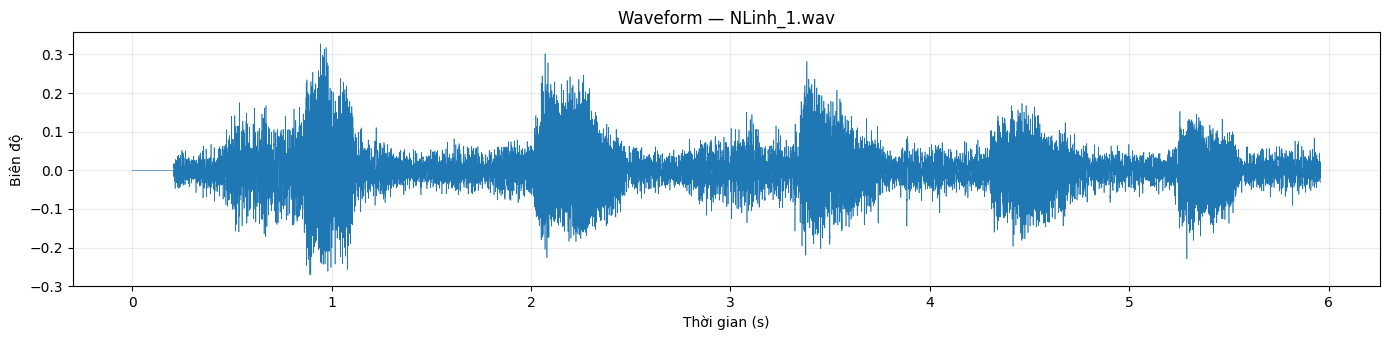

In [2]:
# Chuyển stereo thành mono nếu cần
y = audio.mean(axis=1) if audio.ndim == 2 else audio.copy()
y = y.astype(np.float32)
time = np.arange(len(y)) / sr

rms = np.sqrt(np.mean(y.astype(np.float64) ** 2))
peak = np.max(np.abs(y))
crest_db = 20 * np.log10((peak + 1e-12) / (rms + 1e-12))
print(f"Duration: {len(y)/sr:.3f} s")
print(f"RMS amplitude: {rms:.6f}")
print(f"Peak amplitude: {peak:.6f}")
print(f"Crest factor: {crest_db:.2f} dB")

plt.figure(figsize=(14, 3.5))
plt.plot(time, y, linewidth=0.45)
plt.title("Waveform — NLinh_1.wav")
plt.xlabel("Thời gian (s)")
plt.ylabel("Biên độ")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

RMS:
$$
\mathrm{RMS}=\sqrt{\frac1N\sum_{n=0}^{N-1}y[n]^2}
$$
Bình phương để tránh mẫu âm/dương triệt tiêu, lấy trung bình rồi căn bậc hai. Crest factor:
$$
C=20\log_{10}\frac{\max_n|y[n]|}{\mathrm{RMS}}
$$
Đây là tỷ lệ mức đỉnh so với mức trung bình, không phải chỉ số chất lượng duy nhất.

In [3]:
# Phát âm thanh trực tiếp trong notebook
display(Audio(y, rate=sr))

## 12. Chia khung và năng lượng khung

Dùng frame 25 ms và hop 10 ms để minh họa. Với tần số lấy mẫu $f_s$, số mẫu mỗi khung là $L=0.025f_s$, bước nhảy là $H=0.010f_s$. Năng lượng trung bình:
$$
E_t=\frac1L\sum_{n=0}^{L-1}y_t[n]^2,\qquad \mathrm{RMS}_t=\sqrt{E_t}
$$

Ví dụ khung ngắn $[0.1,-0.2,0.1,0]$:
$$
E=(0.01+0.04+0.01+0)/4=0.015,\quad \mathrm{RMS}=\sqrt{0.015}\approx0.1225
$$
Đây là ví dụ tính tay; code tính trên hàng trăm mẫu mỗi khung. Ngưỡng năng lượng chỉ phát hiện vùng âm thanh sơ bộ, không phải VAD hoàn chỉnh.

Frame: 1200 samples = 25 ms
Hop: 480 samples = 10 ms
Overlap: 60.0%
Number of frames: 595


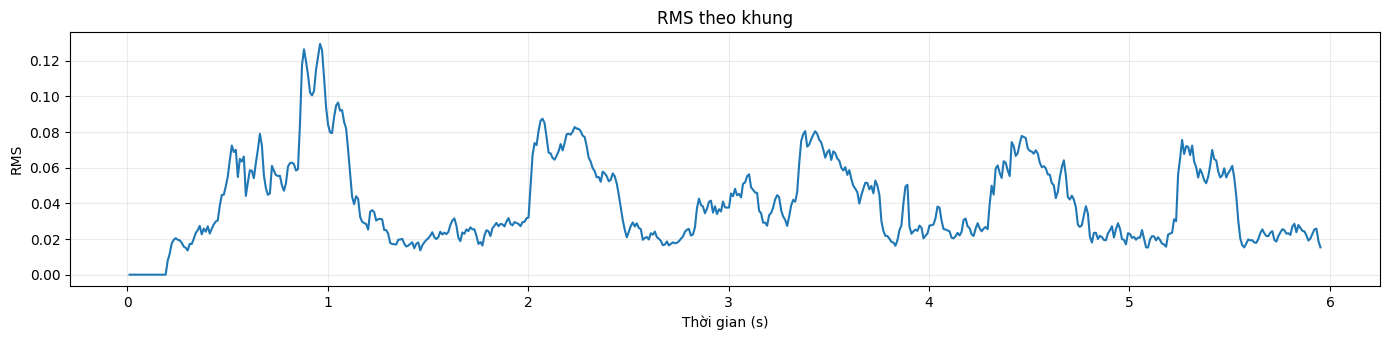

In [4]:
frame_ms, hop_ms = 25, 10
frame_len = int(round(sr * frame_ms / 1000))
hop_len = int(round(sr * hop_ms / 1000))

def frame_signal(signal, frame_length, hop_length):
    """Tách thành các khung và đệm zero ở cuối nếu cần."""
    if len(signal) < frame_length:
        signal = np.pad(signal, (0, frame_length - len(signal)))
    n_frames = 1 + int(np.ceil((len(signal) - frame_length) / hop_length))
    total_len = (n_frames - 1) * hop_length + frame_length
    padded = np.pad(signal, (0, max(0, total_len - len(signal))))
    return np.stack([
        padded[i*hop_length:i*hop_length+frame_length]
        for i in range(n_frames)
    ])

frames = frame_signal(y, frame_len, hop_len)
frame_rms = np.sqrt(np.mean(frames.astype(np.float64)**2, axis=1))
frame_time = (np.arange(len(frames))*hop_len + frame_len/2) / sr

print(f"Frame: {frame_len} samples = {frame_ms} ms")
print(f"Hop: {hop_len} samples = {hop_ms} ms")
print(f"Overlap: {100*(frame_len-hop_len)/frame_len:.1f}%")
print("Number of frames:", len(frames))

plt.figure(figsize=(14, 3.5))
plt.plot(frame_time, frame_rms)
plt.title("RMS theo khung")
plt.xlabel("Thời gian (s)")
plt.ylabel("RMS")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Ngưỡng RMS minh họa: 0.041926
Tỷ lệ khung vượt ngưỡng: 41.5%


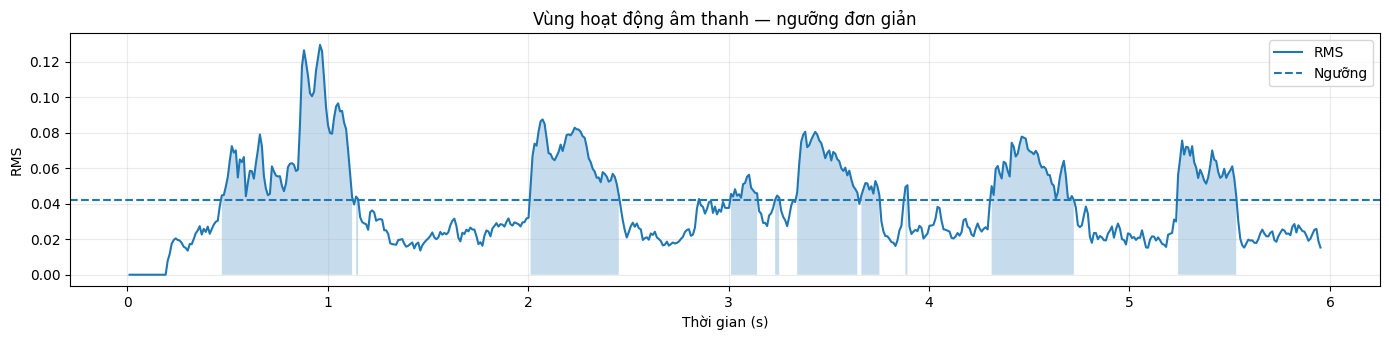

In [5]:
# Ngưỡng RMS tương đối để xem vùng hoạt động âm thanh (chỉ minh họa)
threshold = max(np.percentile(frame_rms, 20) * 2.0, 0.005)
active = frame_rms > threshold
print(f"Ngưỡng RMS minh họa: {threshold:.6f}")
print(f"Tỷ lệ khung vượt ngưỡng: {active.mean()*100:.1f}%")

plt.figure(figsize=(14, 3.5))
plt.plot(frame_time, frame_rms, label="RMS")
plt.axhline(threshold, linestyle="--", label="Ngưỡng")
plt.fill_between(frame_time, 0, frame_rms, where=active, alpha=0.25)
plt.title("Vùng hoạt động âm thanh — ngưỡng đơn giản")
plt.xlabel("Thời gian (s)")
plt.ylabel("RMS")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 13. STFT, Mel-spectrogram và MFCC

Cấu hình minh họa:
- `n_fft=2048`: kích thước FFT.
- cửa sổ Hann dài khoảng 25 ms.
- `hop_length` khoảng 10 ms.
- 40 dải Mel.
- 13 hệ số MFCC.

STFT cho cấu trúc tần số theo thời gian; Mel-spectrogram gom phổ theo thang Mel; MFCC nén hình dạng phổ log-Mel thành ít hệ số. Khi đổi sampling rate hoặc tham số, giá trị MFCC sẽ thay đổi.

STFT shape (frequency bins, frames): (1025, 597)
Mel shape (bands, frames): (40, 597)
MFCC shape (coefficients, frames): (13, 597)


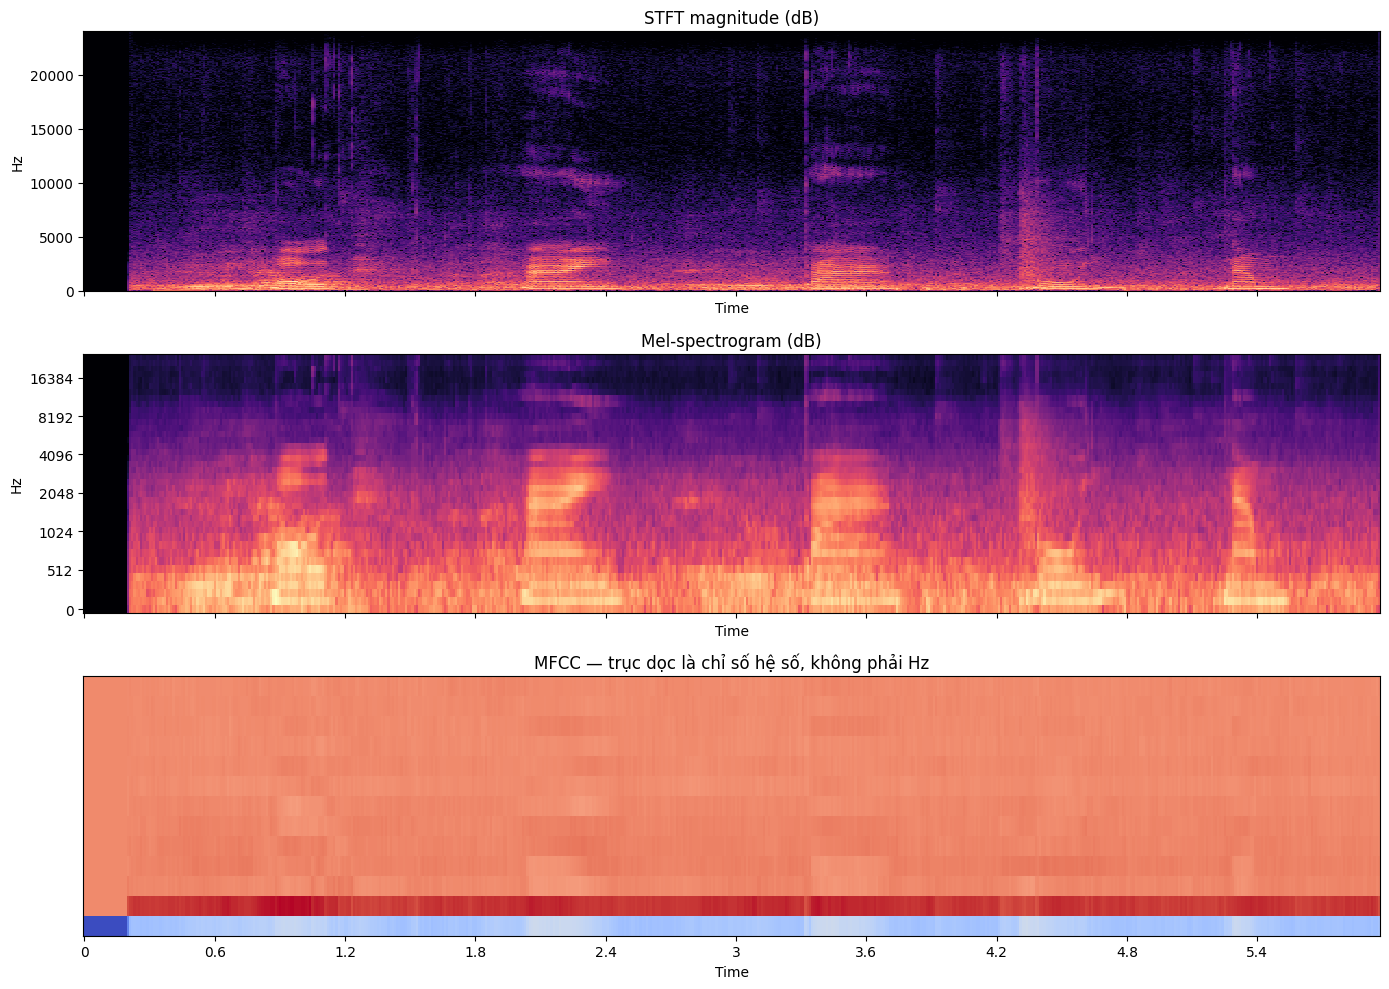

In [6]:
import librosa
import librosa.display

n_fft = 2048
win_length = min(int(round(0.025 * sr)), n_fft)
hop_length = int(round(0.010 * sr))
n_mels, n_mfcc = 40, 13

D = librosa.stft(
    y, n_fft=n_fft, hop_length=hop_length,
    win_length=win_length, window="hann", center=True
)
mel_power = librosa.feature.melspectrogram(
    y=y, sr=sr, n_fft=n_fft, hop_length=hop_length,
    win_length=win_length, window="hann", n_mels=n_mels, power=2.0
)
mel_db = librosa.power_to_db(mel_power, ref=np.max)
mfcc = librosa.feature.mfcc(
    y=y, sr=sr, S=mel_db, n_mfcc=n_mfcc, dct_type=2, norm="ortho"
)

print("STFT shape (frequency bins, frames):", D.shape)
print("Mel shape (bands, frames):", mel_power.shape)
print("MFCC shape (coefficients, frames):", mfcc.shape)

fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
librosa.display.specshow(
    librosa.amplitude_to_db(np.abs(D), ref=np.max),
    sr=sr, hop_length=hop_length, x_axis="time", y_axis="hz", ax=axes[0]
)
axes[0].set_title("STFT magnitude (dB)")
librosa.display.specshow(
    mel_db, sr=sr, hop_length=hop_length, x_axis="time", y_axis="mel", ax=axes[1]
)
axes[1].set_title("Mel-spectrogram (dB)")
librosa.display.specshow(
    mfcc, sr=sr, hop_length=hop_length, x_axis="time", ax=axes[2]
)
axes[2].set_title("MFCC — trục dọc là chỉ số hệ số, không phải Hz")
plt.tight_layout()
plt.show()

### Đọc kết quả

- **STFT:** trục dọc là tần số Hz; màu biểu thị độ lớn phổ theo dB.
- **Mel-spectrogram:** trục dọc là dải Mel; màu biểu thị năng lượng log.
- **MFCC:** trục dọc là chỉ số hệ số. Hệ số không phải một tần số vật lý cụ thể; chúng mô tả các thành phần hình dạng phổ.

MFCC có thể có giá trị âm hoặc dương. Không nên kết luận “giọng người/AI” bằng mắt chỉ từ các hình này.

In [7]:
# Delta và delta-delta
delta = librosa.feature.delta(mfcc, order=1, width=9, mode="nearest")
delta2 = librosa.feature.delta(mfcc, order=2, width=9, mode="nearest")
features_39 = np.vstack([mfcc, delta, delta2]).T

print("MFCC:", mfcc.shape)
print("Delta:", delta.shape)
print("Delta-delta:", delta2.shape)
print("Ghép 13 + 13 + 13 (frames, 39):", features_39.shape)

preview = pd.DataFrame(
    features_39[:5, :9],
    columns=[f"feature_{i}" for i in range(9)]
)
preview.insert(0, "frame", np.arange(len(preview)))
display(preview.round(3))

MFCC: (13, 597)
Delta: (13, 597)
Delta-delta: (13, 597)
Ghép 13 + 13 + 13 (frames, 39): (597, 39)


,frame,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8
0,0,-505.963989,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1,-505.963989,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,2,-505.963989,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,3,-505.963989,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,4,-505.963989,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Delta mô tả thay đổi của đặc trưng theo thời gian; delta-delta mô tả thay đổi bậc hai. Công thức delta thường dùng:
$$
\Delta c_t=\frac{\sum_{n=1}^{K}n(c_{t+n}-c_{t-n})}
{2\sum_{n=1}^{K}n^2}
$$
Nếu $K=2$, mẫu số là $2(1^2+2^2)=2(1+4)=10$. Với 13 MFCC, ghép thêm 13 delta và 13 delta-delta tạo 39 chiều mỗi khung.

Đây vẫn chỉ là ma trận đặc trưng. Chưa có mô hình đã huấn luyện, nhãn tham chiếu hay bộ giải mã, nên chưa tạo transcript hoặc kết luận phân loại.

In [8]:
# Thống kê MFCC của clip
mfcc_stats = pd.DataFrame({
    "mean": mfcc.mean(axis=1),
    "std": mfcc.std(axis=1),
    "min": mfcc.min(axis=1),
    "max": mfcc.max(axis=1),
}, index=[f"MFCC_{i}" for i in range(n_mfcc)])
display(mfcc_stats.round(4))

,mean,std,min,max
MFCC_0,-289.916412,47.495399,-505.964386,-218.614395
MFCC_1,102.221901,21.762899,0.000000,137.069702
MFCC_2,0.391400,8.588400,-26.996799,23.154100
MFCC_3,9.536300,9.269400,-18.899500,29.534000
MFCC_4,9.091900,5.712400,-7.762400,29.889000
MFCC_5,6.193900,6.211000,-17.241301,19.864000
MFCC_6,1.003700,6.862800,-28.890200,15.889300
MFCC_7,-4.417200,4.467800,-17.777800,9.796600
MFCC_8,1.441200,4.334600,-7.919000,16.219500
MFCC_9,-2.643800,3.764500,-17.317400,8.183700


## 14. Liên hệ với bài toán phân biệt giọng người và giọng AI

Nếu mục tiêu là phân loại `human` và `AI-generated`, MFCC/Mel có thể là baseline, nhưng cần:
1. Thu thập nhiều file từ nhiều người nói và nhiều hệ TTS/voice conversion.
2. Xác minh nhãn thủ công hoặc bằng nguồn đáng tin; không dùng hashtag làm nhãn cuối nếu chưa kiểm chứng.
3. Tách train/validation/test theo người nói hoặc nguồn âm thanh để tránh rò rỉ.
4. Huấn luyện baseline (SVM/Logistic Regression trên thống kê MFCC) hoặc CNN trên log-Mel.
5. Đánh giá precision, recall, F1 và confusion matrix, không chỉ accuracy.
6. Kiểm tra độ bền khi đổi micro, codec, ngôn ngữ và hệ thống TTS.

**Không thể kết luận file `NLinh_1.wav` là giọng người hay AI chỉ bằng waveform/MFCC.** Một file đơn lẻ đủ để thực hành trích xuất đặc trưng, không đủ để huấn luyện và đánh giá bộ phân loại.

## Tài liệu tham khảo

- Huang, X., Acero, A., & Hon, H.-W., *Spoken Language Processing*, Chương 9 “Acoustic Modeling”.
- Librosa, tài liệu `mfcc`: https://librosa.org/doc/main/api/generated/librosa.feature.mfcc.html
- Librosa, tài liệu `delta`: https://librosa.org/doc/main/generated/librosa.feature.delta.html

Lý thuyết và thuật ngữ được tổ chức theo chương sách; ví dụ tính tay là ví dụ minh họa. Phần code là bài thực hành bổ sung.